In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("Ambiente preparado com sucesso!")

print("Versão do pandas:", pd.__version__)
print("Versão do NumPy:", np.__version__)

Ambiente preparado com sucesso!
Versão do pandas: 2.2.3
Versão do NumPy: 2.1.3


In [35]:
print("Ambiente preparado com sucesso!")

print("Versão do pandas:", pd.__version__)
print("Versão do NumPy:", np.__version__)

Ambiente preparado com sucesso!
Versão do pandas: 2.2.3
Versão do NumPy: 2.1.3


In [36]:

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

print("Dataset carregado com sucesso!")


Dataset carregado com sucesso!


In [37]:

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [38]:

print("Quantidade de linhas e colunas:", df.shape)
print("Quantidade de transações:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

Quantidade de linhas e colunas: (284807, 31)
Quantidade de transações: 284807
Quantidade de colunas: 31


In [39]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [40]:

df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [41]:

df["Class"].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


In [42]:

contagem = df["Class"].value_counts().sort_index()

resumo = pd.DataFrame({
    "Tipo de transação": ["Normal", "Fraude"],
    "Quantidade": contagem.values,
    "Percentual (%)": (
        contagem.values / len(df) * 100
    ).round(4)
})

resumo


,Tipo de transação,Quantidade,Percentual (%)
0,Normal,284315,99.8273
1,Fraude,492,0.1727


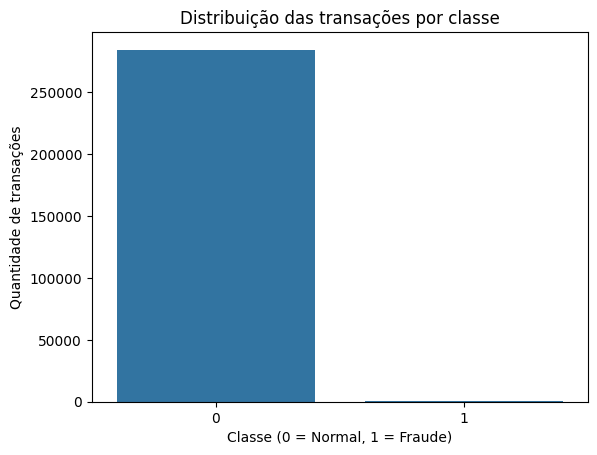

In [43]:

sns.countplot(data=df, x="Class")

plt.title("Distribuição das transações por classe")
plt.xlabel("Classe (0 = Normal, 1 = Fraude)")
plt.ylabel("Quantidade de transações")
plt.show()

In [44]:

df["Amount_log"] = np.log1p(df["Amount"])

df[["Amount", "Amount_log"]].head()

,Amount,Amount_log
0,149.62,5.014760
1,2.69,1.305626
2,378.66,5.939276
3,123.50,4.824306
4,69.99,4.262539


In [45]:

X = df.drop(columns=["Class", "Time"])
y = df["Class"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Formato de X: (284807, 30)
Formato de y: (284807,)


In [46]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nProporção de fraudes no treino:")
print(y_train.value_counts(normalize=True) * 100)

print("\nProporção de fraudes no teste:")
print(y_test.value_counts(normalize=True) * 100)

Treino: (227845, 30)
Teste: (56962, 30)

Proporção de fraudes no treino:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64

Proporção de fraudes no teste:
Class
0    99.827955
1     0.172045
Name: proportion, dtype: float64


In [47]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Formato do treino padronizado:", X_train_scaled.shape)
print("Formato do teste padronizado:", X_test_scaled.shape)

Formato do treino padronizado: (227845, 30)
Formato do teste padronizado: (56962, 30)


In [48]:

print("Média da primeira variável no treino:",
      X_train_scaled[:, 0].mean())

print("Desvio padrão da primeira variável no treino:",
      X_train_scaled[:, 0].std())

Média da primeira variável no treino: 8.420046024939193e-19
Desvio padrão da primeira variável no treino: 1.0


In [49]:
from sklearn.linear_model import LogisticRegression

modelo_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [50]:
modelo_lr.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [51]:
y_pred = modelo_lr.predict(X_test_scaled)

print("Quantidade de previsões:", len(y_pred))
print("Primeiras 20 previsões:", y_pred[:20])

Quantidade de previsões: 56962
Primeiras 20 previsões: [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [52]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_test, y_pred)

print(matriz)

[[55418  1446]
 [    8    90]]


In [53]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fraude"],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9999    0.9746    0.9871     56864
      Fraude     0.0586    0.9184    0.1102        98

    accuracy                         0.9745     56962
   macro avg     0.5292    0.9465    0.5486     56962
weighted avg     0.9982    0.9745    0.9855     56962



In [54]:
y_prob = modelo_lr.predict_proba(X_test_scaled)[:, 1]

print("Primeiras 10 probabilidades de fraude:")
print(y_prob[:10])

Primeiras 10 probabilidades de fraude:
[5.96976817e-03 5.72581475e-02 1.11954193e-04 1.81159999e-02
 9.27367734e-01 1.78221272e-02 1.37292744e-03 2.70396677e-02
 5.49213069e-02 4.29201034e-03]


In [55]:
y_pred_80 = (y_prob >= 0.80).astype(int)

print("Matriz de confusão com limiar de 80%:")
print(confusion_matrix(y_test, y_pred_80))

Matriz de confusão com limiar de 80%:
[[56422   442]
 [   10    88]]


In [56]:
print(classification_report(
    y_test,
    y_pred_80,
    target_names=["Normal", "Fraude"],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9998    0.9922    0.9960     56864
      Fraude     0.1660    0.8980    0.2803        98

    accuracy                         0.9921     56962
   macro avg     0.5829    0.9451    0.6381     56962
weighted avg     0.9984    0.9921    0.9948     56962



In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

def avaliar_limiar(y_real, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    return {
        "Limiar": limiar,
        "Precisão": precision_score(y_real, previsoes),
        "Recall": recall_score(y_real, previsoes),
        "F1-score": f1_score(y_real, previsoes)
    }

print(avaliar_limiar(y_test, y_prob, 0.80))

{'Limiar': 0.8, 'Precisão': 0.1660377358490566, 'Recall': 0.8979591836734694, 'F1-score': 0.2802547770700637}


In [58]:
limiares = [0.10, 0.30, 0.50, 0.70, 0.80]

resultados = []

for limiar in limiares:
    resultado = avaliar_limiar(y_test, y_prob, limiar)
    resultados.append(resultado)

df_limiares = pd.DataFrame(resultados)

df_limiares.round(4)

,Limiar,Precisão,Recall,F1-score
0,0.1,0.0081,0.9490,0.0161
1,0.3,0.0266,0.9184,0.0518
2,0.5,0.0586,0.9184,0.1102
3,0.7,0.1158,0.8980,0.2051
4,0.8,0.1660,0.8980,0.2803


In [59]:
limiares_altos = [0.85, 0.90, 0.95, 0.99]

resultados_altos = []

for limiar in limiares_altos:
    resultado = avaliar_limiar(y_test, y_prob, limiar)
    resultados_altos.append(resultado)

df_limiares_altos = pd.DataFrame(resultados_altos)

df_limiares_altos.round(4)

,Limiar,Precisão,Recall,F1-score
0,0.85,0.1934,0.8980,0.3183
1,0.90,0.2536,0.8878,0.3946
2,0.95,0.4047,0.8878,0.5559
3,0.99,0.5685,0.8469,0.6803


In [60]:
df_comparacao = pd.concat(
    [df_limiares, df_limiares_altos],
    ignore_index=True
)

df_comparacao = df_comparacao.sort_values("Limiar")

df_comparacao.round(4)

,Limiar,Precisão,Recall,F1-score
0,0.10,0.0081,0.9490,0.0161
1,0.30,0.0266,0.9184,0.0518
2,0.50,0.0586,0.9184,0.1102
3,0.70,0.1158,0.8980,0.2051
4,0.80,0.1660,0.8980,0.2803
5,0.85,0.1934,0.8980,0.3183
6,0.90,0.2536,0.8878,0.3946
7,0.95,0.4047,0.8878,0.5559
8,0.99,0.5685,0.8469,0.6803


In [61]:

df_comparacao = df_comparacao.sort_values("Limiar").reset_index(drop=True)

display(df_comparacao.round(4))

,Limiar,Precisão,Recall,F1-score
0,0.10,0.0081,0.9490,0.0161
1,0.30,0.0266,0.9184,0.0518
2,0.50,0.0586,0.9184,0.1102
3,0.70,0.1158,0.8980,0.2051
4,0.80,0.1660,0.8980,0.2803
5,0.85,0.1934,0.8980,0.3183
6,0.90,0.2536,0.8878,0.3946
7,0.95,0.4047,0.8878,0.5559
8,0.99,0.5685,0.8469,0.6803


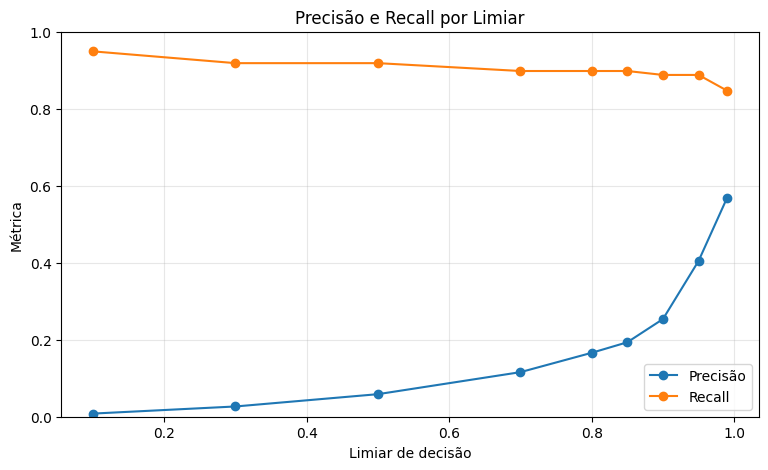

In [62]:

plt.figure(figsize=(9, 5))

plt.plot(
    df_comparacao["Limiar"],
    df_comparacao["Precisão"],
    marker="o",
    label="Precisão"
)

plt.plot(
    df_comparacao["Limiar"],
    df_comparacao["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Limiar de decisão")
plt.ylabel("Métrica")
plt.title("Precisão e Recall por Limiar")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

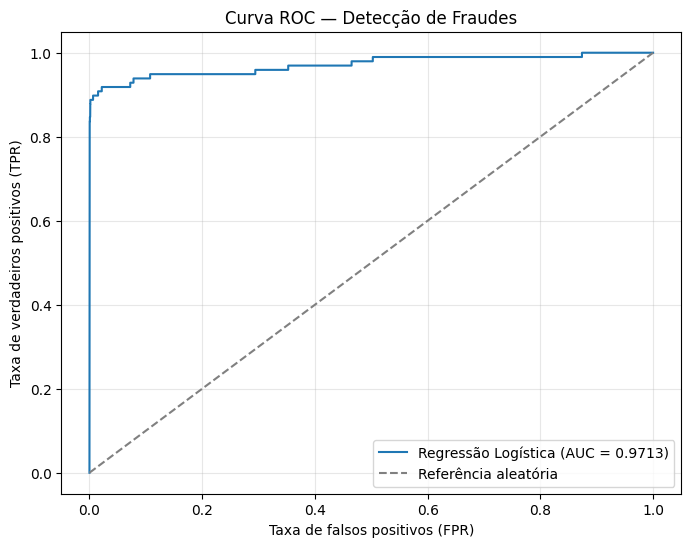

AUC-ROC: 0.9713


In [63]:

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, limiares_roc = roc_curve(y_test, y_prob)

auc_roc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Regressão Logística (AUC = {auc_roc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray",
         label="Referência aleatória")

plt.xlabel("Taxa de falsos positivos (FPR)")
plt.ylabel("Taxa de verdadeiros positivos (TPR)")
plt.title("Curva ROC — Detecção de Fraudes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"AUC-ROC: {auc_roc:.4f}")

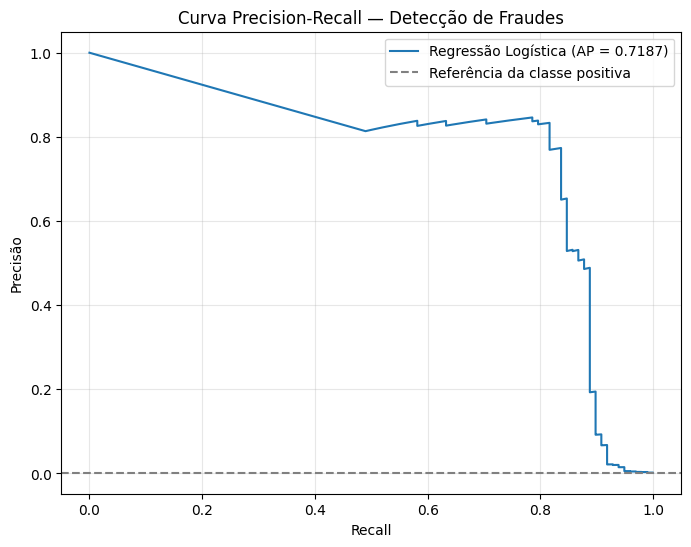

Average Precision (AP): 0.7187


In [64]:

from sklearn.metrics import precision_recall_curve, average_precision_score

precisions, recalls, limiares_pr = precision_recall_curve(
    y_test,
    y_prob
)

average_precision = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    recalls,
    precisions,
    label=f"Regressão Logística (AP = {average_precision:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Referência da classe positiva"
)

plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curva Precision-Recall — Detecção de Fraudes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Average Precision (AP): {average_precision:.4f}")

In [65]:

from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [33]:

modelo_rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [66]:

modelo_rf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [67]:

print("Modelo treinado:", hasattr(modelo_rf, "estimators_"))
print("Quantidade de árvores:", len(modelo_rf.estimators_)
      if hasattr(modelo_rf, "estimators_") else 0)

Modelo treinado: True
Quantidade de árvores: 200


In [68]:

y_pred_rf = modelo_rf.predict(X_test_scaled)

print("Quantidade de previsões:", len(y_pred_rf))
print("Primeiras 20 previsões:", y_pred_rf[:20])

Quantidade de previsões: 56962
Primeiras 20 previsões: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [69]:

from sklearn.metrics import confusion_matrix

matriz_rf = confusion_matrix(y_test, y_pred_rf)

print(matriz_rf)

[[56861     3]
 [   23    75]]


In [70]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Normal", "Fraude"],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9996    0.9999    0.9998     56864
      Fraude     0.9615    0.7653    0.8523        98

    accuracy                         0.9995     56962
   macro avg     0.9806    0.8826    0.9260     56962
weighted avg     0.9995    0.9995    0.9995     56962



In [71]:

y_prob_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

print("Primeiras 10 probabilidades de fraude:")
print(y_prob_rf[:10])

Primeiras 10 probabilidades de fraude:
[0.   0.   0.01 0.   0.   0.   0.   0.   0.   0.  ]


In [72]:

import numpy as np

np.set_printoptions(precision=6, suppress=True)

print("Primeiras 10 probabilidades de fraude:")
print(y_prob_rf[:10])

print("\nMaior probabilidade de fraude:")
print(y_prob_rf.max())

Primeiras 10 probabilidades de fraude:
[0.   0.   0.01 0.   0.   0.   0.   0.   0.   0.  ]

Maior probabilidade de fraude:
1.0


In [73]:

from sklearn.metrics import confusion_matrix, classification_report

limiar_rf = 0.20

y_pred_rf_20 = (y_prob_rf >= limiar_rf).astype(int)

print("Matriz de confusão — limiar 0,20:")
print(confusion_matrix(y_test, y_pred_rf_20))

print("\nRelatório de classificação:")
print(classification_report(
    y_test,
    y_pred_rf_20,
    target_names=["Normal", "Fraude"],
    digits=4,
    zero_division=0
))

Matriz de confusão — limiar 0,20:
[[56849    15]
 [   16    82]]

Relatório de classificação:
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56864
      Fraude     0.8454    0.8367    0.8410        98

    accuracy                         0.9995     56962
   macro avg     0.9225    0.9182    0.9204     56962
weighted avg     0.9995    0.9995    0.9995     56962



In [74]:

comparacao_modelos = pd.DataFrame([
    {
        "Modelo": "Regressão Logística",
        "Limiar": 0.50,
        "Precisão": 0.0586,
        "Recall": 0.9184,
        "F1-score": 0.1102
    },
    {
        "Modelo": "Regressão Logística",
        "Limiar": 0.80,
        "Precisão": 0.1660,
        "Recall": 0.8980,
        "F1-score": 0.2803
    },
    {
        "Modelo": "Random Forest",
        "Limiar": 0.50,
        "Precisão": 0.9615,
        "Recall": 0.7653,
        "F1-score": 0.8523
    },
    {
        "Modelo": "Random Forest",
        "Limiar": 0.20,
        "Precisão": 0.8454,
        "Recall": 0.8367,
        "F1-score": 0.8410
    }
])

display(comparacao_modelos.round(4))

,Modelo,Limiar,Precisão,Recall,F1-score
0,Regressão Logística,0.5,0.0586,0.9184,0.1102
1,Regressão Logística,0.8,0.1660,0.8980,0.2803
2,Random Forest,0.5,0.9615,0.7653,0.8523
3,Random Forest,0.2,0.8454,0.8367,0.8410


As 10 variáveis mais importantes:


,Importância
V14,0.188250
V4,0.127516
V10,0.124212
V17,0.095680
V12,0.074217
V11,0.068169
V3,0.058192
V7,0.032333
V16,0.028104
V2,0.019723


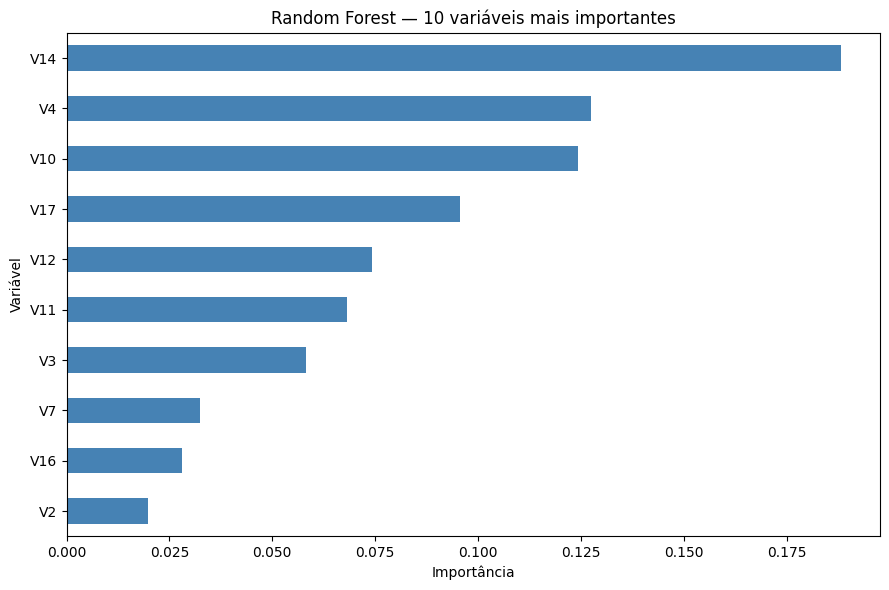

In [76]:

import pandas as pd
import matplotlib.pyplot as plt

importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("As 10 variáveis mais importantes:")
display(importancias.head(10).to_frame("Importância"))

importancias.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue"
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title("Random Forest — 10 variáveis mais importantes")
plt.tight_layout()
plt.show()

In [77]:

try:
    import shap
    print("SHAP instalado. Versão:", shap.__version__)
except ImportError:
    print("SHAP não está instalado.")

SHAP instalado. Versão: 0.52.0


In [78]:

import shap

# Seleciona 200 transações do conjunto de teste
X_shap = X_test_scaled[:200]

print("Formato da amostra:", X_shap.shape)

Formato da amostra: (200, 30)


In [79]:

explainer = shap.TreeExplainer(modelo_rf)

shap_values = explainer.shap_values(X_shap)

print("Tipo do resultado:", type(shap_values))
print("Formato do resultado:", getattr(shap_values, "shape", None))

Tipo do resultado: <class 'numpy.ndarray'>
Formato do resultado: (200, 30, 2)


In [80]:

# Seleciona os valores SHAP da classe fraude (1)
shap_fraude = shap_values[:, :, 1]

print("Formato das explicações de fraude:", shap_fraude.shape)

Formato das explicações de fraude: (200, 30)


10 variáveis mais importantes segundo o SHAP:


,Importância SHAP
V12,0.067857
V14,0.067834
V4,0.063652
V3,0.045245
V10,0.045221
V11,0.044632
V17,0.029373
V16,0.016906
V1,0.012828
V9,0.012769


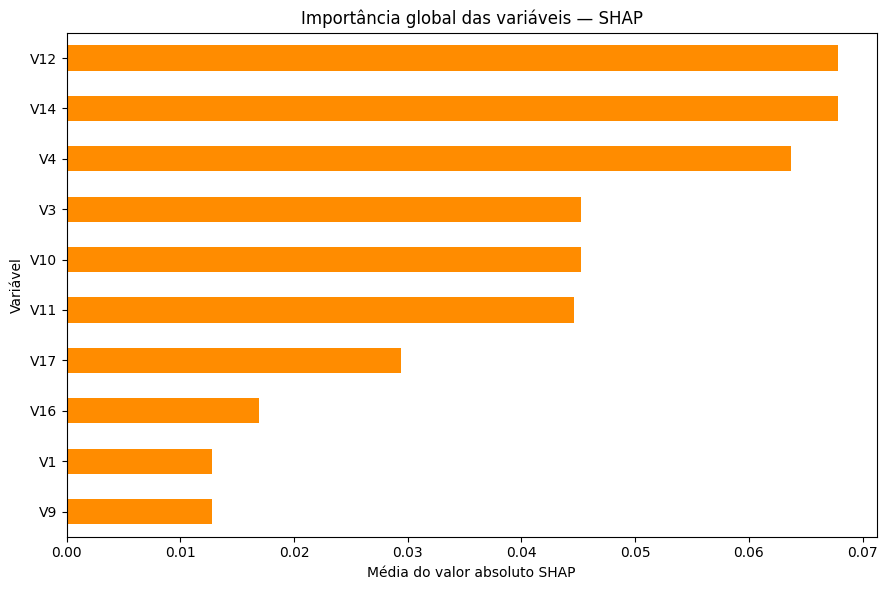

In [81]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

importancia_shap = pd.Series(
    np.abs(shap_fraude).mean(axis=0),
    index=X_train.columns
).sort_values(ascending=False)

print("10 variáveis mais importantes segundo o SHAP:")
display(importancia_shap.head(10).to_frame("Importância SHAP"))

importancia_shap.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    color="darkorange"
)

plt.xlabel("Média do valor absoluto SHAP")
plt.ylabel("Variável")
plt.title("Importância global das variáveis — SHAP")
plt.tight_layout()
plt.show()

In [82]:

# Índices das transações classificadas como fraude
# e que realmente eram fraude
indices_corretos = np.where(
    (y_pred_rf == 1) & (np.asarray(y_test) == 1)
)[0]

print("Quantidade de fraudes identificadas corretamente:",
      len(indices_corretos))

# Seleciona a primeira transação desse grupo
indice_local = indices_corretos[0]

print("Índice da transação no conjunto de teste:", indice_local)
print("Probabilidade estimada de fraude:",
      y_prob_rf[indice_local])

Quantidade de fraudes identificadas corretamente: 75
Índice da transação no conjunto de teste: 840
Probabilidade estimada de fraude: 0.975


In [83]:

# Seleciona a transação 840 do conjunto de teste
X_caso = X_test_scaled[indice_local:indice_local + 1]

# Calcula os valores SHAP para essa transação
shap_caso = explainer.shap_values(X_caso)

print("Formato dos valores SHAP:", shap_caso.shape)

Formato dos valores SHAP: (1, 30, 2)


In [84]:

# Seleciona as contribuições para a classe fraude
shap_caso_fraude = shap_caso[0, :, 1]

# Organiza as contribuições com os nomes das variáveis
contribuicoes = pd.Series(
    shap_caso_fraude,
    index=X_train.columns
)

# Exibe as 10 maiores contribuições positivas e negativas
print("Variáveis que mais favoreceram a classificação como fraude:")
display(contribuicoes.sort_values(ascending=False).head(10).to_frame("SHAP"))

print("Variáveis que mais desfavoreceram a classificação como fraude:")
display(contribuicoes.sort_values().head(10).to_frame("SHAP"))

Variáveis que mais favoreceram a classificação como fraude:


,SHAP
V14,0.138532
V10,0.100440
V17,0.080298
V12,0.067316
V4,0.052408
V11,0.040917
V3,0.023051
V16,0.022374
V7,0.017109
V21,0.006134


Variáveis que mais desfavoreceram a classificação como fraude:


,SHAP
V20,-0.013572
V8,-0.010362
V19,-0.007226
V26,-0.006749
V24,-0.006632
V1,-0.005980
V13,-0.005948
V5,-0.005565
V18,-0.005009
V15,-0.004167


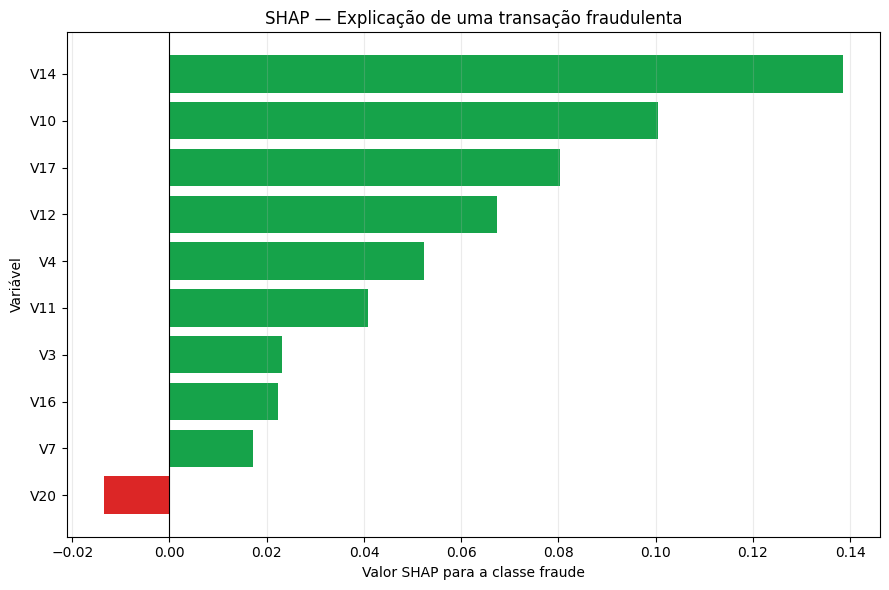

In [85]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Seleciona as 10 contribuições de maior magnitude
top_caso = contribuicoes.loc[
    contribuicoes.abs().sort_values(ascending=False).head(10).index
].sort_values()

cores = [
    "#DC2626" if valor < 0 else "#16A34A"
    for valor in top_caso.values
]

plt.figure(figsize=(9, 6))
plt.barh(top_caso.index, top_caso.values, color=cores)
plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Valor SHAP para a classe fraude")
plt.ylabel("Variável")
plt.title("SHAP — Explicação de uma transação fraudulenta")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

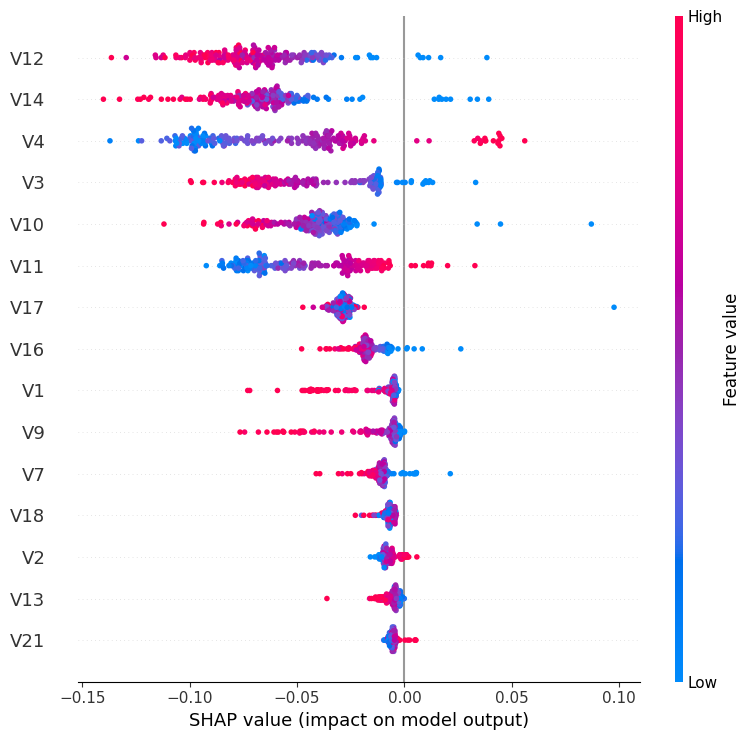

In [86]:

shap.summary_plot(
    shap_fraude,
    X_shap,
    feature_names=X_train.columns.tolist(),
    plot_type="dot",
    max_display=15
)